In [1]:
from utils import df_transform, X_datasets_transform, plot_confusion_matrix

import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.metrics import roc_auc_score, classification_report, accuracy_score, f1_score
import optuna

In [2]:
df = pd.read_csv("titanic.csv", index_col= 'PassengerId')

In [3]:
df = df_transform(df)

In [4]:
X = df.drop(columns = ['Survived', 'Name'])
y = df['Survived']

In [5]:
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size = 0.8, shuffle = True, stratify=y, random_state = 0)

In [6]:
X_train, X_test = X_datasets_transform(X_train, X_test)

In [7]:
X_train.head(5)

,Pclass,Is_Male,Deck,Family_size,Wealth_level,Section_bow,Section_midship,Section_midship_aft,Section_stern,Embarked_C,Embarked_Q,Embarked_S,Age_normalized,Fare_per_person_log
PassengerId,,,,,,,,,,,,,,
503,3,0,3,1,5,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.296306,2.155152
465,3,1,2,1,5,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.296306,2.202765
199,3,0,2,1,5,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.296306,2.169054
766,1,0,3,2,3,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.635587,3.688358
422,3,1,2,1,5,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.258608,2.202765


In [8]:
X_test.head(5)

,Pclass,Is_Male,Deck,Family_size,Wealth_level,Section_bow,Section_midship,Section_midship_aft,Section_stern,Embarked_C,Embarked_Q,Embarked_S,Age_normalized,Fare_per_person_log
PassengerId,,,,,,,,,,,,,,
154,3,1,-1.0,3,4,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.503644,2.740840
753,3,1,-1.0,1,5,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.409399,2.351375
611,3,0,-1.0,7,5,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.484795,1.826563
201,3,1,-1.0,1,5,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.346569,2.351375
311,1,0,2.0,1,2,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.296306,4.432700


# Baseline

In [9]:
from sklearn.dummy import DummyClassifier

In [10]:
dummy = DummyClassifier(strategy='most_frequent', random_state=0)
dummy.fit(X_train, y_train)
y_pred_dummy = dummy.predict(X_test)

In [11]:
y_proba_test = dummy.predict_proba(X_test)
roc_auc_test_dummy = roc_auc_score(y_test, y_proba_test[:,1])
print(f"Dummy Train ROC AUC: {roc_auc_test_dummy:.3f}")

Dummy Train ROC AUC: 0.500


In [12]:
print(classification_report(y_test, y_pred_dummy, zero_division=0))
acc_dummy = accuracy_score(y_test, y_pred_dummy)
f1_dummy = f1_score(y_test, y_pred_dummy)

              precision    recall  f1-score   support

           0       0.61      1.00      0.76       110
           1       0.00      0.00      0.00        69

    accuracy                           0.61       179
   macro avg       0.31      0.50      0.38       179
weighted avg       0.38      0.61      0.47       179



Most-frequent strategy predicts everything as '0' and hits 61% accuracy.

# SVC

The SVC model looks for hyperplane that separates the classes with the largest possible margin. The model is highly sensative to the feature scaling.

Hyperparameters:

C - controls the margin. A small C value leads to a higher tolerance for misclassifications and a wider margin.

Kernel - the type of kernel function used to project data into higher dimensions in order to find non-linear decision boundaries.

Gamma - the range of influence of a single training point. A large Gamma value leads to a narrow range of influence, increasing the risk of overfitting (the model tries to fit every individual point).

In [13]:
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

In [14]:
def objective(trial):

    params = {
        'C' : trial.suggest_float("C", 0.1, 100, log = True),
        'gamma' : trial.suggest_float("gamma", 0.001, 0.1, log = True),
        'kernel' : 'rbf',
    }

    svc = SVC(**params, probability=True, random_state = 0)

    clf = make_pipeline(StandardScaler(), svc)

    cv = StratifiedKFold(n_splits=5, shuffle= True, random_state=0)

    roc_auc = cross_val_score(clf, X_train, y_train, cv=cv, scoring='roc_auc').mean()

    return roc_auc

The StandardScaler transforms the data separately for each training subset within the cross-validation.

The StratifiedKFold preserves the class distribution across all CV folds.

The 'roc-auc' metric evaluates the model's ability to distinguish between classes independently of the decision threshold (which defaults to 50%).

In [15]:
study_svc = optuna.create_study(study_name='svc', direction="maximize", sampler = optuna.samplers.TPESampler(seed=0),
                                storage="sqlite:///svc_study.db", load_if_exists=True)

[I 2026-10-02 20:19:29,024] A new study created in RDB with name: svc


In [16]:
study_svc.optimize(objective, n_trials=50)

[I 2026-10-02 20:19:29,229] Trial 0 finished with value: 0.8515115100851778 and parameters: {'C': 4.430375245218266, 'gamma': 0.02693883019285411}. Best is trial 0 with value: 0.8515115100851778.
[I 2026-10-02 20:19:29,412] Trial 1 finished with value: 0.8414970499139779 and parameters: {'C': 6.431172050131989, 'gamma': 0.012296071107325713}. Best is trial 0 with value: 0.8515115100851778.
[I 2026-10-02 20:19:29,587] Trial 2 finished with value: 0.8458130943710881 and parameters: {'C': 1.8662266976517967, 'gamma': 0.019578897201213006}. Best is trial 0 with value: 0.8515115100851778.
[I 2026-10-02 20:19:29,770] Trial 3 finished with value: 0.8521458313542952 and parameters: {'C': 2.0547625125911337, 'gamma': 0.060749960734256966}. Best is trial 3 with value: 0.8521458313542952.
[I 2026-10-02 20:19:29,988] Trial 4 finished with value: 0.8421617955943976 and parameters: {'C': 77.80155576901412, 'gamma': 0.005846326121643413}. Best is trial 3 with value: 0.8521458313542952.
[I 2026-10-02 

In [17]:
import optuna.visualization as vis

In [18]:
vis.plot_optimization_history(study_svc)

In [19]:
print("Best hyperparameters:", study_svc.best_params)
print("Best roc_auc:", study_svc.best_value)

Best hyperparameters: {'C': 0.88846958447213, 'gamma': 0.006546585279494658}
Best roc_auc: 0.8551877975153838


In [20]:
best_svc_model = make_pipeline(StandardScaler(), SVC(**study_svc.best_params, probability=True, random_state=0))

In [21]:
best_svc_model.fit(X_train, y_train)

,steps,"[('standardscaler', ...), ('svc', ...)]"
,transform_input,None
,memory,None
,verbose,False
,copy,True
,with_mean,True
,with_std,True
,C,0.88846958447213
,kernel,'rbf'
,degree,3
,gamma,0.006546585279494658


In [22]:
y_proba_train = best_svc_model.predict_proba(X_train)
roc_auc_train_svc = roc_auc_score(y_train, y_proba_train[:,1])
print(f"SVC Train ROC AUC: {roc_auc_train_svc:.3f}")

y_proba_test = best_svc_model.predict_proba(X_test)
roc_auc_test_svc = roc_auc_score(y_test,  y_proba_test[:,1])
print(f"SVC Test ROC AUC:  {roc_auc_test_svc:.3f}")

SVC Train ROC AUC: 0.867
SVC Test ROC AUC:  0.829


In [23]:
y_pred_svc = best_svc_model.predict(X_test)
acc_svc = accuracy_score(y_test, y_pred_svc)
f1_svc = f1_score(y_test, y_pred_svc)

In [24]:
print(classification_report(y_test, y_pred_svc))

              precision    recall  f1-score   support

           0       0.81      0.86      0.83       110
           1       0.75      0.67      0.71        69

    accuracy                           0.79       179
   macro avg       0.78      0.77      0.77       179
weighted avg       0.79      0.79      0.78       179



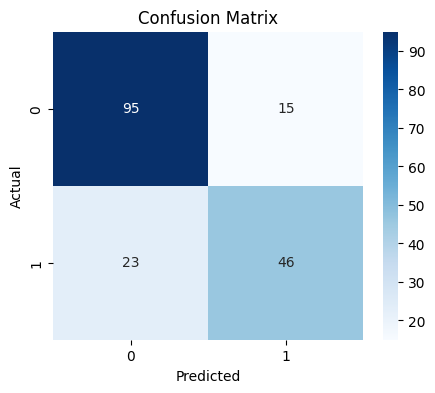

In [25]:
plot_confusion_matrix(y_test, y_pred_svc)

The SVC achieved an overall accuracy of ~79%. The model produces both false positives and false negatives.

In [26]:
import joblib
joblib.dump(best_svc_model, 'titanic_svc_model.joblib')

['titanic_svc_model.joblib']

# XGBoost

The XGBoost model combines decision trees, where each tree learns from the mistakes of the previous one. The model is robust to feature scaling and handles variables selection automatically.

Hyperparameters:

learning rate - the percantage of contribution that each individual tree adds to the final prediction.

max_depth - the maximum depth of a tree.

n_estimators - the total number of trees.

subsample - the percentage of samples used by an individual tree.

colsample_bytree - the percentage of features randomly sampled for each tree.

min_child_weight - the minimum sum of samples required inside a leaf node to perform a further split.

gamma - the minimum loss reduction required to further split.

reg_alpha - L1 regularization term, which prunes less important leaf adjustments smaller than the alpha threshold.

reg_lambda - L2 regularization term, which shrinks the magnitude of all leaf adjustments.


In [27]:
from xgboost import XGBClassifier

In [28]:
def objective(trial):

    params = {
    'learning_rate' : trial.suggest_float("learning_rate", 0.01, 0.1),
    'max_depth' : trial.suggest_int("max_depth", 2, 4),
    'n_estimators' : trial.suggest_int("n_estimators", 50, 100),
    'subsample' : trial.suggest_float("subsample", 0.6, 0.8, step = 0.1),
    'colsample_bytree' : trial.suggest_float("colsample_bytree", 0.4, 0.7, step=0.1),
    'min_child_weight' : trial.suggest_int('min_child_weight', 4, 10),
    'gamma' : trial.suggest_float("gamma", 0, 5),
    'reg_alpha' : trial.suggest_float("reg_alpha", 0.0, 1.0),
    'reg_lambda' : trial.suggest_float( "reg_lambda", 1.0, 10.0),
    }

    clf = XGBClassifier(
        **params,
        objective='binary:logistic',
        eval_metric="auc",
        tree_method="hist",
        device="cuda",
        random_state = 0
    )

    roc_auc = cross_val_score(clf, X_train, y_train, cv=5, scoring="roc_auc").mean()

    return roc_auc

In [29]:
xgb_study = optuna.create_study(study_name='svc', direction="maximize", sampler = optuna.samplers.TPESampler(seed=0),
                                storage="sqlite:///xgb_study.db", load_if_exists=True)

[I 2026-10-02 20:19:39,502] A new study created in RDB with name: svc


In [30]:
xgb_study.optimize(objective, n_trials=50)

c:\Users\Veronika\AppData\Local\Programs\Python\Python310\lib\site-packages\xgboost\core.py:751: UserWarning: [20:19:42] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\common\error_msg.cc:62: Falling back to prediction using DMatrix due to mismatched devices. This might lead to higher memory usage and slower performance. XGBoost is running on: cuda:0, while the input data is on: cpu.
Potential solutions:
- Use a data structure that matches the device ordinal in the booster.
- Set the device for booster before call to inplace_predict.

This warning will only be shown once.

  return func(**kwargs)
[I 2026-10-02 20:19:42,393] Trial 0 finished with value: 0.8468972641778286 and parameters: {'learning_rate': 0.05939321535345923, 'max_depth': 4, 'n_estimators': 80, 'subsample': 0.7, 'colsample_bytree': 0.5, 'min_child_weight': 8, 'gamma': 2.1879360563134624, 'reg_alpha': 0.8917730007820798, 'reg_lambda': 9.672964844509263}. Best is trial 0 with value: 0.8468972641778286.
[I 2026-10-02

In [31]:
vis.plot_optimization_history(xgb_study)

In [32]:
print("Best hyperparameters:", xgb_study.best_params)
print("Best roc_auc:", xgb_study.best_value)

Best hyperparameters: {'learning_rate': 0.09147223274189986, 'max_depth': 4, 'n_estimators': 94, 'subsample': 0.7, 'colsample_bytree': 0.7, 'min_child_weight': 4, 'gamma': 0.30728220870599987, 'reg_alpha': 0.10425438586231893, 'reg_lambda': 4.175797263045854}
Best roc_auc: 0.8756640068395554


In [33]:
best_xgb_model = XGBClassifier(**xgb_study.best_params, random_state=0)

In [34]:
best_xgb_model.fit(X_train, y_train)

,objective,'binary:logistic'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,0.7
,device,None
,early_stopping_rounds,None
,enable_categorical,False
,eval_metric,None


In [35]:
y_proba_train = best_xgb_model.predict_proba(X_train)
roc_auc_train_xgb = roc_auc_score(y_train, y_proba_train[:,1])
print(f"XGBoost Train ROC AUC: {roc_auc_train_xgb:.3f}")

y_proba_test = best_xgb_model.predict_proba(X_test)
roc_auc_test_xgb = roc_auc_score(y_test,  y_proba_test[:,1])
print(f"XGBoost Test ROC AUC:  {roc_auc_test_xgb:.3f}")

XGBoost Train ROC AUC: 0.926
XGBoost Test ROC AUC:  0.872


In [36]:
y_pred_xgb = best_xgb_model.predict(X_test)
acc_xgb = accuracy_score(y_test, y_pred_xgb)
f1_xgb = f1_score(y_test, y_pred_xgb)

In [37]:
print(classification_report(y_test, y_pred_xgb))

              precision    recall  f1-score   support

           0       0.83      0.91      0.87       110
           1       0.83      0.70      0.76        69

    accuracy                           0.83       179
   macro avg       0.83      0.80      0.81       179
weighted avg       0.83      0.83      0.82       179



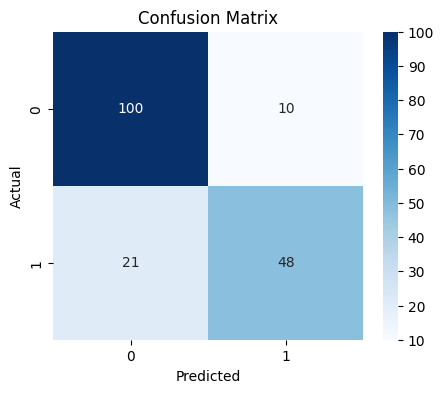

In [38]:
plot_confusion_matrix(y_test, y_pred_xgb)

The XGBoost achieved an overall accuracy of ~83%, but classifies survivors as dead twice as often as it classifies dead as survivors.

In [39]:
import joblib
joblib.dump(best_xgb_model, 'titanic_xgb_model.joblib')

['titanic_xgb_model.joblib']

In [40]:
from xgboost import plot_importance

<Figure size 800x600 with 0 Axes>

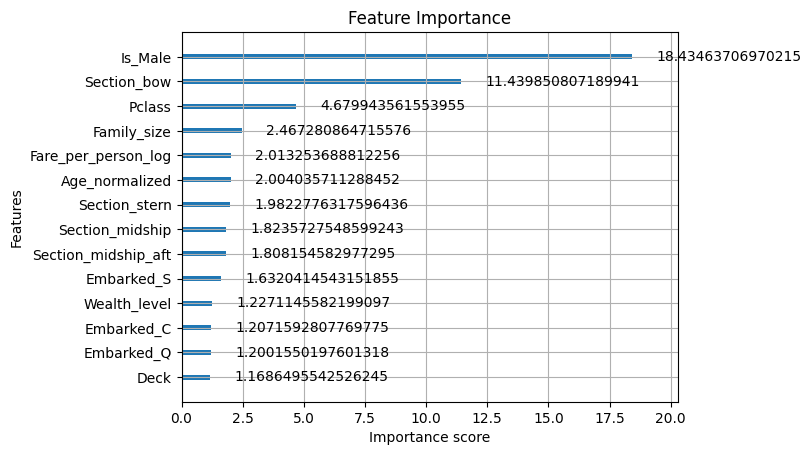

In [41]:
plt.figure(figsize=(8,6))
plot_importance(best_xgb_model, importance_type="gain")
plt.title("Feature Importance")
plt.show()

The most influential features for the model turned out to be sex, whether a passenger was located in the bow, and passenger class.

# Model Comparison

In [50]:
print(f"Baseline: Accuracy = {acc_dummy * 100:.2f}%,  F1 = {f1_dummy * 100:.2f}%,   ROC_AUC = {roc_auc_test_dummy * 100:.2f}%")
print(f"SVC:      Accuracy = {acc_svc * 100:.2f}%,  F1 = {f1_svc * 100:.2f}%,  ROC_AUC = {roc_auc_test_svc * 100:.2f}%")
print(f"XGboost:  Accuracy = {acc_xgb * 100:.2f}%,  F1 = {f1_xgb * 100:.2f}%,  ROC_AUC = {roc_auc_test_xgb * 100:.2f}%")

Baseline: Accuracy = 61.45%,  F1 = 0.00%,   ROC_AUC = 50.00%
SVC:      Accuracy = 78.77%,  F1 = 70.77%,  ROC_AUC = 82.92%
XGboost:  Accuracy = 82.68%,  F1 = 75.59%,  ROC_AUC = 87.17%


Both SVC and XGBoost outperformed the baseline, but XGBoost delivers better performance.